# Topology and routing

A lattice allows two-qubit gates only between neighbours. By default a twin rejects a circuit that breaks this, so a
program never pays a hidden cost. Routing is opt-in, and it reports exactly what it did.

QPUTwin at http://localhost:8000: ready, 4 twins reachable


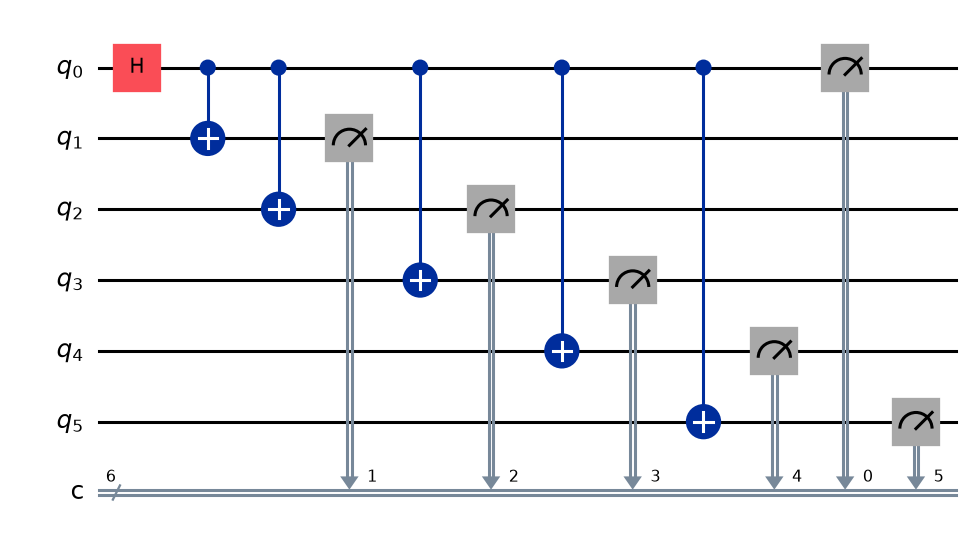

In [1]:
from qputwin_demo import *

connect()
circuit = star_ghz(6)
draw(circuit)

## Enforced, not hidden

Without routing, logical qubit $i$ is physical qubit $i$, and physical qubits 0 and 2 are not coupled. The twin refuses,
names the statement and lists each qubit's real neighbours. Routing could not embed this star either: qubit 0 talks to
five others, and a lattice qubit has at most four neighbours.

In [2]:
rejected = run("iqm_emerald", circuit)
error = rejected["error"]

print("HTTP", rejected["http_status"], error["type"])
print(error["message"])
pd.Series(error["details"]).to_frame("value")

HTTP 422 TopologicalCompilationError
'cx q[0],q[2];' (line 7) requires a two-qubit interaction between physical qubits 0 and 2, which are not coupled on iqm_emerald (grid 6x9, nearest-neighbour only; no routing)


,value
device,iqm_emerald
gate,cx
primitive,CX
qubits,"[0, 2]"
line,7
statement,"cx q[0],q[2];"
neighbors,"{'0': [1, 9], '2': [1, 3, 11]}"
adjacency_entry,0


## Ask for routing

In [3]:
routed = run("iqm_emerald", circuit, routing=True, shots=4096)
stats = routed["compilation"]["routing"]

pd.Series({
    "HTTP status": routed["http_status"],
    "Layout trials": stats["trials"],
    "SWAPs inserted": stats["swaps_inserted"],
    "Two-qubit gates before": stats["input_two_qubit_gates"],
    "Two-qubit gates after": routed["compilation"]["native_two_qubit_count"],
    "Physical qubits used": routed["compilation"]["physical_qubits_used"],
    "Logical → physical at start": dict(stats["initial_layout"]),
    "Logical → physical at end": dict(stats["final_layout"]),
}).to_frame("value")

,value
HTTP status,200
Layout trials,16
SWAPs inserted,1
Two-qubit gates before,5
Two-qubit gates after,6
Physical qubits used,"[13, 14, 15, 22, 23, 24]"
Logical → physical at start,"{0: 23, 1: 22, 2: 24, 3: 13, 4: 15, 5: 14}"
Logical → physical at end,"{0: 14, 1: 22, 2: 24, 3: 13, 4: 15, 5: 23}"


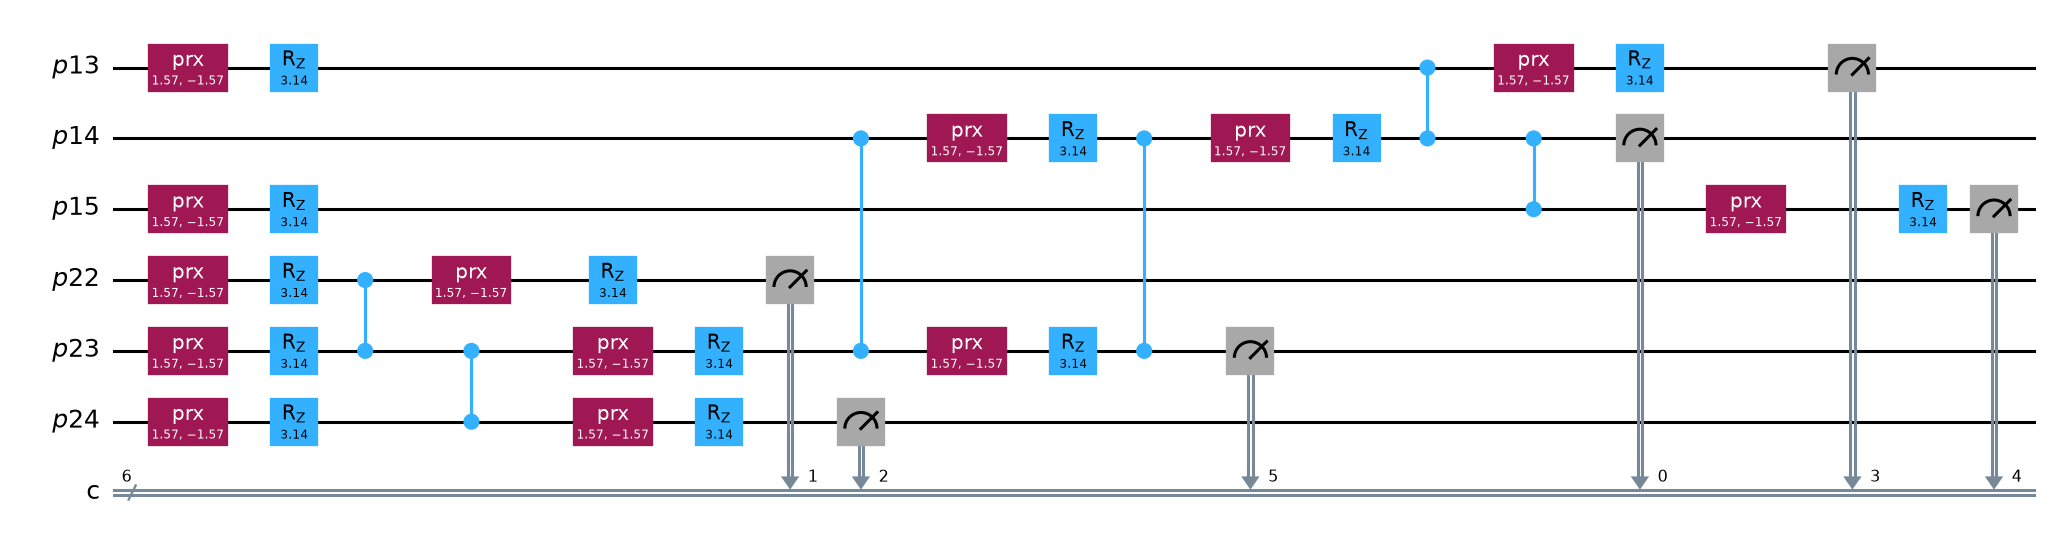

In [4]:
draw_native(routed, circuit, routing=True, fold=36)

## Where it landed

The highlighted qubits are the ones this job used on the 6×9 lattice, which is synthetic, as notebook 01 showed.

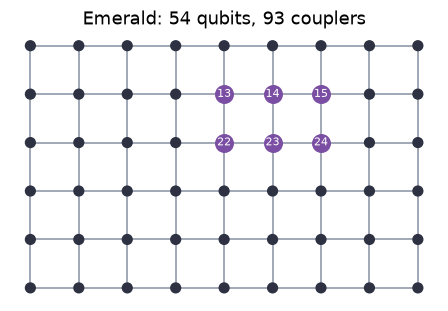

In [5]:
plot_topology("iqm_emerald", highlight=routed["compilation"]["physical_qubits_used"]);

## Exact layout first

If a circuit's interaction graph fits inside the device graph, no SWAP is needed at all. A GHZ chain embeds as a path.

SWAPs: 0 | Physical path: [40, 41, 29, 17, 5, 4, 16, 28, 27, 39]


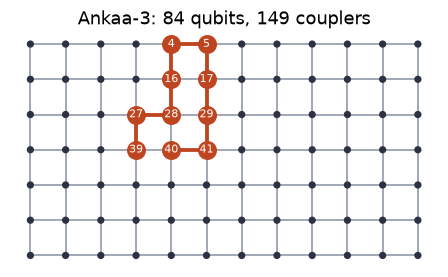

In [6]:
circuit = ghz(10)
routed = run("rigetti_ankaa_3", circuit, routing=True)
stats = routed["compilation"]["routing"]
layout = [physical for _, physical in sorted(stats["initial_layout"])]

print("SWAPs:", stats["swaps_inserted"], "| Physical path:", layout)
plot_topology("rigetti_ankaa_3", highlight=layout, arrows=list(zip(layout, layout[1:])));

## What connectivity costs

A star cannot be embedded in a lattice beyond degree 4, so every extra leaf needs routing. On the all-to-all twins the
gate count stays at $k-1$.

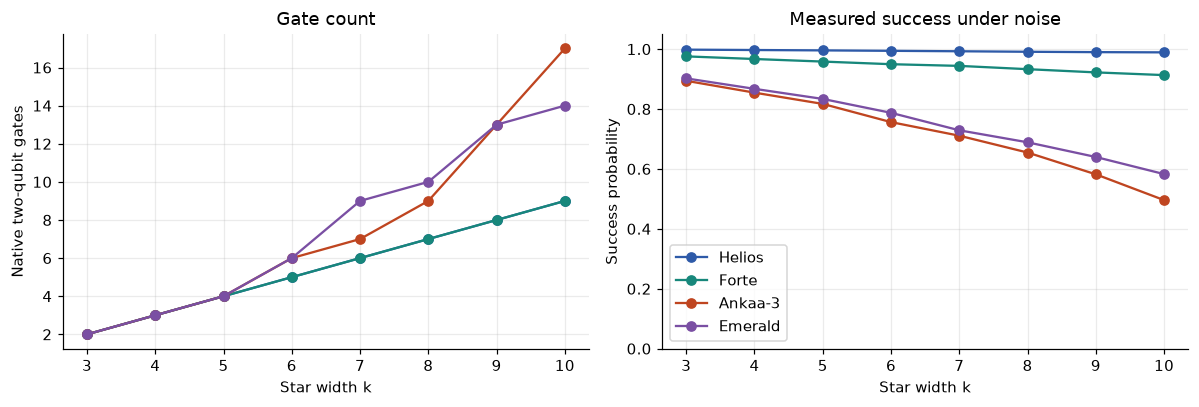

In [7]:
widths = range(3, 11)
rows = []
for backend in BACKENDS:
    for k in widths:
        r = run(backend, star_ghz(k), routing=True, noise=True, shots=4096)
        rows.append({"twin": backend, "k": k, "gates": r["compilation"]["native_two_qubit_count"],
                     "success": success(r, ["0" * k, "1" * k])})
star = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for backend, group in star.groupby("twin", sort=False):
    axes[0].plot(group.k, group.gates, "o-", color=COLORS[backend], label=NAMES[backend])
    axes[1].plot(group.k, group.success, "o-", color=COLORS[backend], label=NAMES[backend])
axes[0].set(xlabel="Star width k", ylabel="Native two-qubit gates", title="Gate count")
axes[1].set(xlabel="Star width k", ylabel="Success probability", title="Measured success under noise", ylim=(0, 1.05))
axes[1].legend()
fig.tight_layout()
plt.show()

## Routing also enlarges the simulation

SABRE moves logical qubits through physical qubits the circuit never named, and those must be simulated too. This is an
effect you see only when compilation and execution live in one system.

In [8]:
cases = {"Mirror, 14 qubits": mirror(14, 5), "QFT round trip, 12 qubits": qft_roundtrip(12, 1234),
         "GHZ chain, 14 qubits": ghz(14)}
rows = []
for name, circuit in cases.items():
    for backend in ("quantinuum_helios", "rigetti_ankaa_3", "iqm_emerald"):
        r = run(backend, circuit, routing=True, shots=256)
        rows.append({"Circuit": name, "Twin": NAMES[backend],
                     "Declared": r["compilation"]["declared_qubits"],
                     "Simulated": r["compilation"]["simulated_qubits"],
                     "SWAPs": r["compilation"]["routing"].get("swaps_inserted", 0),
                     "2Q gates": r["compilation"]["native_two_qubit_count"],
                     "Worker time (ms)": round(r["telemetry"]["breakdown"]["worker_service_ms"], 1)})
pd.DataFrame(rows).set_index(["Circuit", "Twin"])

Declared  Simulated  SWAPs  2Q gates  \
Circuit                   Twin                                            
Mirror, 14 qubits         Helios         14         14      0        70   
                          Ankaa-3        14         14     29       157   
                          Emerald        14         14     36       178   
QFT round trip, 12 qubits Helios         12         12      0       264   
                          Ankaa-3        12         14     81       503   
                          Emerald        12         12     74       480   
GHZ chain, 14 qubits      Helios         14         14      0        13   
                          Ankaa-3        14         14      0        13   
                          Emerald        14         14      0        13   

                                   Worker time (ms)  
Circuit                   Twin                       
Mirror, 14 qubits         Helios               21.5  
                          Ankaa-3             504.9  
                          Emerald             437.6  
QFT round trip, 12 qubits Helios               47.9  
                          Ankaa-3             507.7  
                          Emerald             434.5  
GHZ chain, 14 qubits      Helios                4.5  
                          Ankaa-3               7.2  
                          Emerald               4.5